# Loan Approval Prediction — Data Mining Project (Final Report)

**Team Members:** Fatimah Bin Mohammed, Najd Mohammed Alhargan, Elaf Alangari, Lara Alfurayh

## [1] Problem

Loan approval is an important decision for financial institutions. It is usually done manually by reviewing each applicant's details, which makes the process slow, inconsistent, and prone to bias. A wrong decision can be costly: approving a high-risk applicant may lead to financial loss, while rejecting a reliable applicant means losing a potential customer.

In this project, we use a loan application dataset from Dream Housing Finance to study which applicant characteristics affect loan approval. We aim to build a model that predicts whether a loan application will be approved, and to discover groups of applicants with similar profiles.

This problem is important because data-driven loan decisions can be faster, fairer, and more consistent, and they help institutions understand the key factors behind approval.

## [2] Data Mining Task

The problem is formalized as two data mining tasks:

- **Classification:** Predict the class label **Loan_Status**, which has two classes: **Y** (approved) and **N** (not approved), based on the applicant's attributes. A Decision Tree classifier is used, as it produces interpretable rules that show how the decision is made.
- **Clustering:** Group applicants with similar characteristics without using the class label. K-means clustering is used to discover common applicant profiles and patterns within the data.

## [3] Data

The dataset was obtained from the Kaggle notebook "Loan Prediction Dream Housing Finance" [2].

It contains **614 records** and **13 attributes**, describing each applicant's personal, financial, and loan details. The class attribute is **Loan_Status**.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
url = "https://raw.githubusercontent.com/Engfatiimah/Minig_Project/main/Dataset/Raw_dataset.csv"
df = pd.read_csv(url)

num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
cat_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
            'Credit_History', 'Property_Area']
target = 'Loan_Status'

### Dataset Description

The table below describes the attributes of the dataset.

| Attribute | Description | Type |
|---|---|---|
| Loan_ID | Unique loan identifier | Nominal (ID) |
| Gender | Male / Female | Binary |
| Married | Applicant married (Yes / No) | Binary |
| Dependents | Number of dependents (0, 1, 2, 3+) | Ordinal |
| Education | Graduate / Not Graduate | Binary |
| Self_Employed | Self-employed (Yes / No) | Binary |
| ApplicantIncome | Applicant income | Numeric |
| CoapplicantIncome | Co-applicant income | Numeric |
| LoanAmount | Loan amount (in thousands) | Numeric |
| Loan_Amount_Term | Loan term (in months) | Numeric |
| Credit_History | Credit history meets guidelines (1 / 0) | Binary |
| Property_Area | Urban / Semiurban / Rural | Nominal |
| Loan_Status | Loan approved (Y / N) | Class label |

In [ ]:
print("Number of objects (rows):", df.shape[0])
print("Number of attributes (columns):", df.shape[1])

Number of objects (rows): 614
Number of attributes (columns): 13


In [ ]:
print("Data types of attributes:")
print(df.dtypes)

Data types of attributes:
Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object


**Class Attribute:** Loan_Status

**Class Values:** Y (approved) and N (not approved)

**Class Distribution:** 2 classes, Y → 422 instances and N → 192 instances.

In [ ]:
print("Number of classes:", df[target].nunique())
print("Number of instances for each class:")
print(df[target].value_counts())

Number of classes: 2
Number of instances for each class:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


**Sample of Raw Dataset:**

In [ ]:
print("Sample of the raw dataset:")
display(df.head(10))

Sample of the raw dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


### Data Analysis

This section analyzes the selected dataset using statistical summaries and visualization techniques. The analysis includes statistical summaries, missing values analysis, outlier detection, variable distributions, class label distribution, and different types of plots.

The purpose of this analysis is to understand the characteristics of the dataset and identify issues that may require preprocessing.

#### 1. Statistical Summary

The statistical summary of the numeric attributes shows the count, mean, standard deviation, minimum, Q1, median, Q3, and maximum values.


In [ ]:
df[num_cols].describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
count,614.000000,614.000000,592.000000,600.00000
mean,5403.459283,1621.245798,146.412162,342.00000
std,6109.041673,2926.248369,85.587325,65.12041
min,150.000000,0.000000,9.000000,12.00000
25%,2877.500000,0.000000,100.000000,360.00000
50%,3812.500000,1188.500000,128.000000,360.00000
75%,5795.000000,2297.250000,168.000000,360.00000
max,81000.000000,41667.000000,700.000000,480.00000


The statistical summary shows differences in the distributions of the numerical attributes.

ApplicantIncome has a mean of 5403.46 and a median of 3812.50. Its maximum value (81000) is much higher than Q3 (5795), indicating a right-skewed distribution with some unusually high incomes.

CoapplicantIncome has a mean of 1621.25 and a median of 1188.50, while Q1 is zero. This indicates that at least 25% of applicants have no recorded coapplicant income.

LoanAmount has a mean of 146.41 and a median of 128, with values ranging from 9 to 700. The difference between its mean and median suggests that larger loan amounts affect the average.

Loan_Amount_Term has a mean of 342 and a median of 360. Both Q1 and Q3 are 360, indicating that most recorded loan terms are concentrated around 360 months.

The count values also show that LoanAmount and Loan_Amount_Term contain missing values. These findings support further investigation of missing values, outliers, and numerical distributions before preprocessing.

#### 2. Missing Values Analysis

The dataset was checked to identify missing values in each attribute.

Missing values were found in Gender, Married, Dependents, Self_Employed, LoanAmount, Loan_Amount_Term, and Credit_History.

These missing values indicate that the dataset needs preprocessing.

In [ ]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_values = pd.DataFrame({'Missing Values': missing_count, 'Percentage (%)': missing_percentage.round(2)})

missing_values[missing_values['Missing Values'] > 0]

,Missing Values,Percentage (%)
Gender,13,2.12
Married,3,0.49
Dependents,15,2.44
Self_Employed,32,5.21
LoanAmount,22,3.58
Loan_Amount_Term,14,2.28
Credit_History,50,8.14


The missing values analysis shows that Credit_History has the highest number of missing values (50 records, 8.14%), followed by Self_Employed (32 records, 5.21%) and LoanAmount (22 records, 3.58%).

Married has the fewest missing values (3 records, 0.49%). The remaining affected attributes have missing percentages between 2.12% and 2.44%.

These results indicate that missing values are not equally distributed across attributes. Since Credit_History is relevant to loan approval prediction, handling its missing values is particularly important during preprocessing.

#### 3. Outlier Analysis

Boxplots were used to examine the distribution of the numeric attributes and identify potential outliers.

The boxplots show potential outliers in ApplicantIncome, CoapplicantIncome, LoanAmount, and Loan_Amount_Term.

These potential outliers are examined further using the IQR method below.

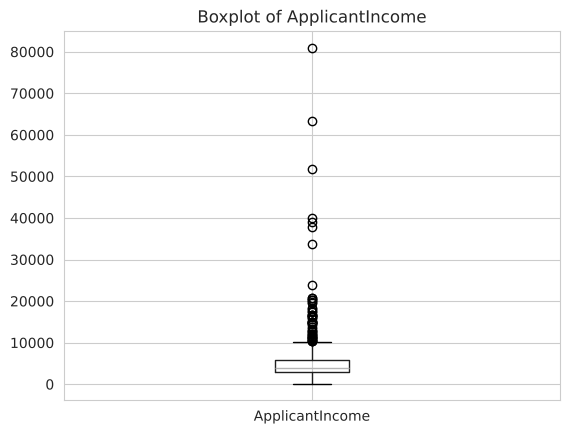

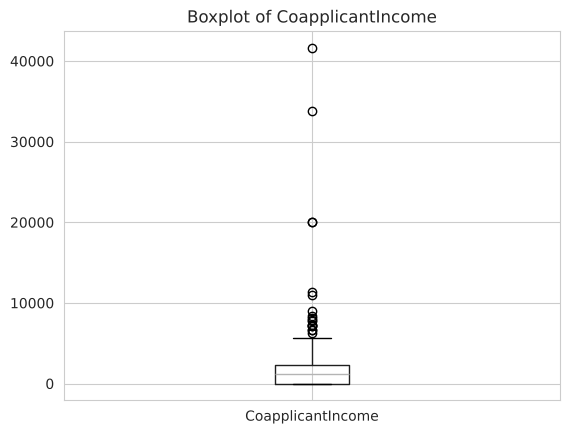

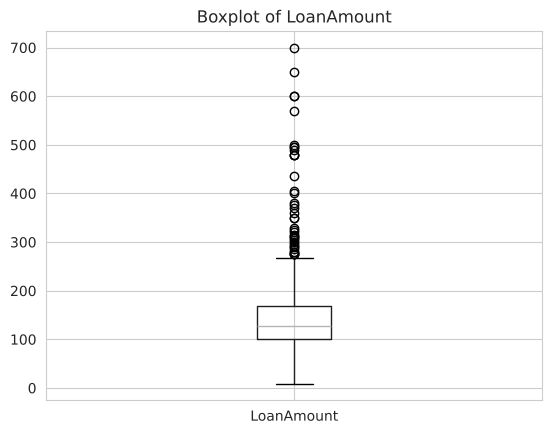

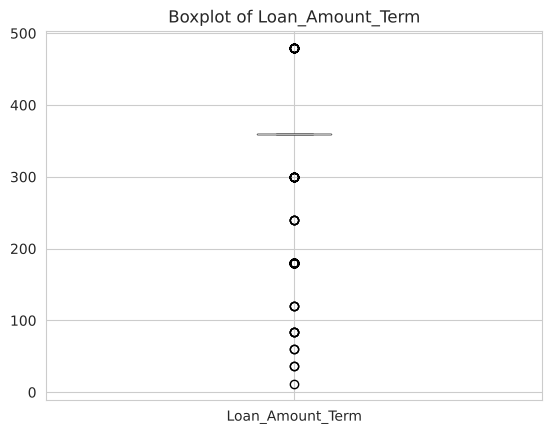

In [ ]:
for col in num_cols:
    df.boxplot(column=col)
    plt.title('Boxplot of ' + col)
    plt.show()

**Outlier Detection Using IQR**

The Interquartile Range (IQR) method was used to identify potential outliers in the numeric attributes.

The IQR is calculated as:

IQR = Q3 - Q1

Values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR are considered potential outliers.

In [ ]:
for col in num_cols:
    data = df[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data < lower_bound) | (data > upper_bound)]

    print(col + ":")
    print(f"Number of potential outliers: {len(outliers)}")
    print()

ApplicantIncome:
Number of potential outliers: 50

CoapplicantIncome:
Number of potential outliers: 18

LoanAmount:
Number of potential outliers: 39

Loan_Amount_Term:
Number of potential outliers: 88



The IQR method identified 50 potential outliers in ApplicantIncome, 18 in CoapplicantIncome, 39 in LoanAmount, and 88 in Loan_Amount_Term.

ApplicantIncome and LoanAmount contain unusually high values, consistent with their statistical summaries and boxplots.

For Loan_Amount_Term, Q1 and Q3 are both 360, resulting in an IQR of zero. Therefore, the IQR method flags loan terms different from 360 as potential outliers, even though they may be valid loan durations.

These results show that potential outliers require careful interpretation and should not automatically be treated as incorrect data or removed.

#### 4. Histograms

The histograms show the distribution of the numeric attributes.

ApplicantIncome, CoapplicantIncome, and LoanAmount are **right-skewed**, where most values are small and few values are very large. Most values of Loan_Amount_Term are 360.

The numeric attributes also have different ranges, so they need to be **normalized** during the preprocessing stage.

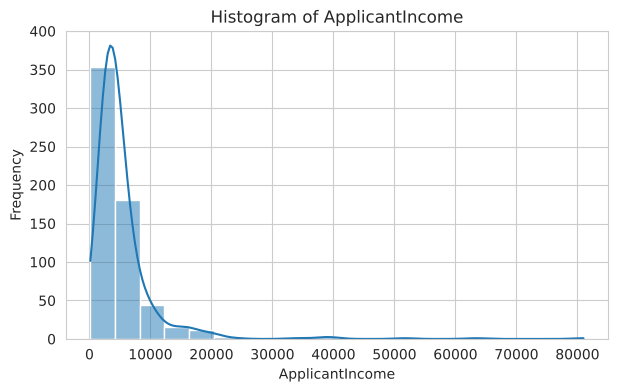

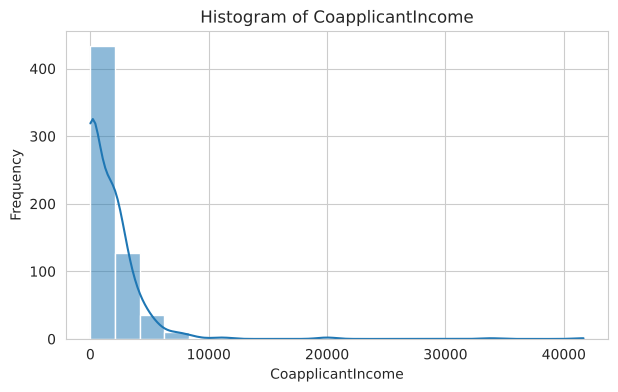

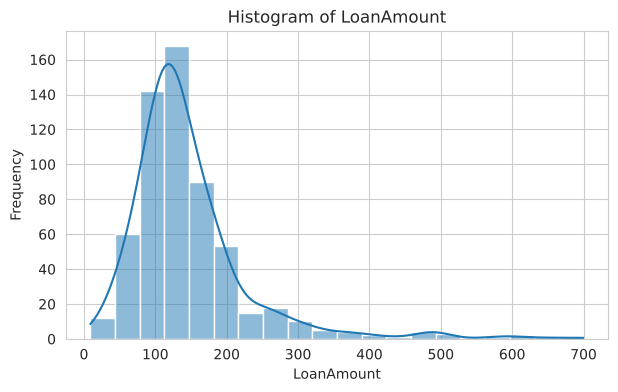

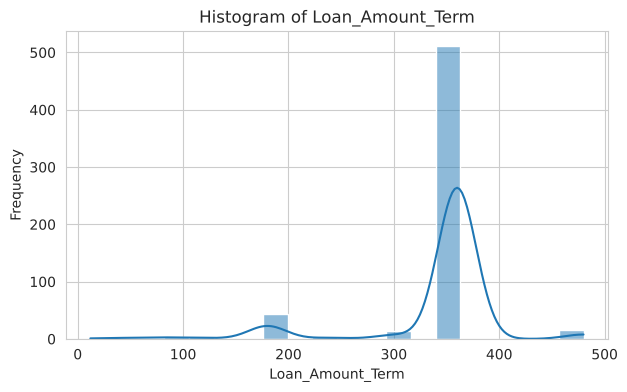

In [ ]:
for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], bins=20, kde=True)
    plt.title('Histogram of ' + col)
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

#### 5. Bar Plots

The bar plots show the frequency of each value in the categorical attributes.

Some attributes are **imbalanced**, such as Gender (489 Male, 112 Female) and Self_Employed (500 No, 82 Yes). Property_Area is the most balanced attribute.

These attributes contain text values, and Dependents contains the value "3+". Therefore, they need to be **encoded** into numeric values before applying the data mining techniques.

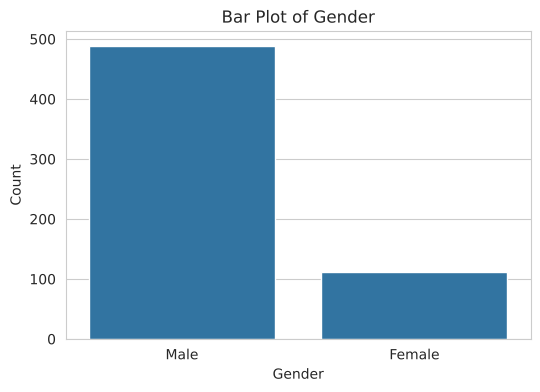

Gender
Male      489
Female    112
Name: count, dtype: int64 



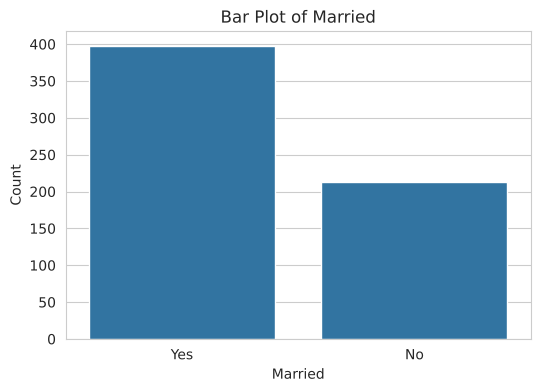

Married
Yes    398
No     213
Name: count, dtype: int64 



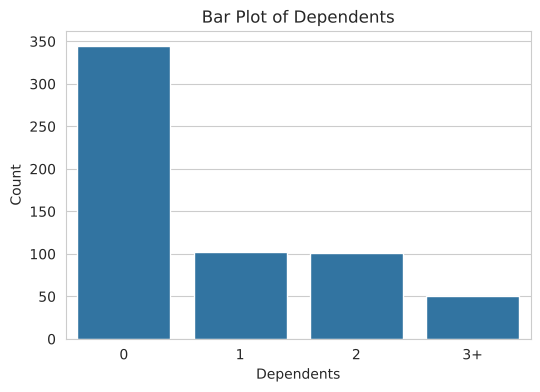

Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64 



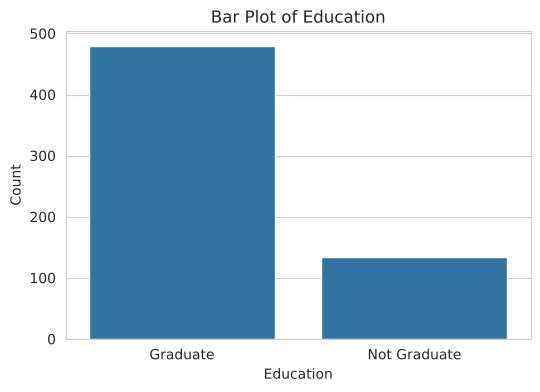

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64 



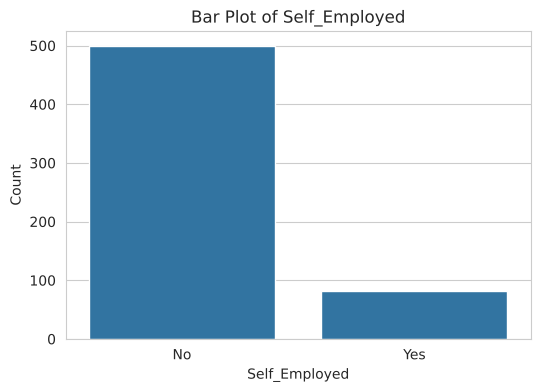

Self_Employed
No     500
Yes     82
Name: count, dtype: int64 



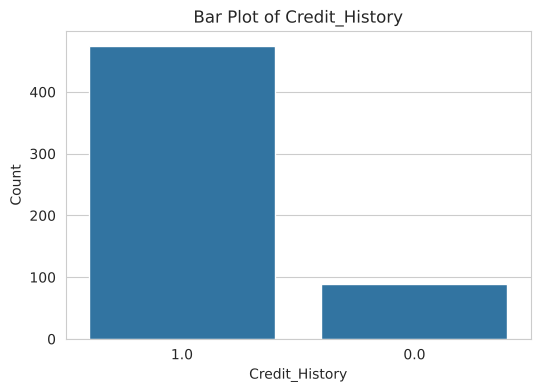

Credit_History
1.0    475
0.0     89
Name: count, dtype: int64 



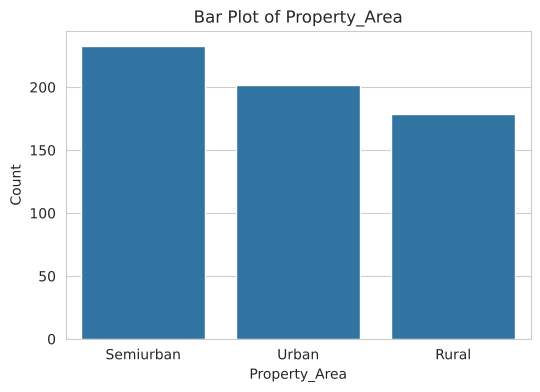

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64 



In [ ]:
for col in cat_cols:
    counts = df[col].value_counts()
    plt.figure(figsize=(6, 4))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title('Bar Plot of ' + col)
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()
    print(counts, '\n')

#### 6. Scatter Plots

The scatter plots show the relationship between LoanAmount and other numeric attributes. The **correlation coefficient (r)** was calculated to measure the strength of each relationship.

ApplicantIncome and LoanAmount have a **positive correlation (r = 0.57)**, which means applicants with higher income usually request larger loans. CoapplicantIncome has a **weak correlation (r = 0.19)**, and Loan_Amount_Term has **almost no correlation (r = 0.04)**.

The plots also show some extreme values that affect the scale, which supports the need for **normalization**.

ApplicantIncome vs LoanAmount   r = 0.57


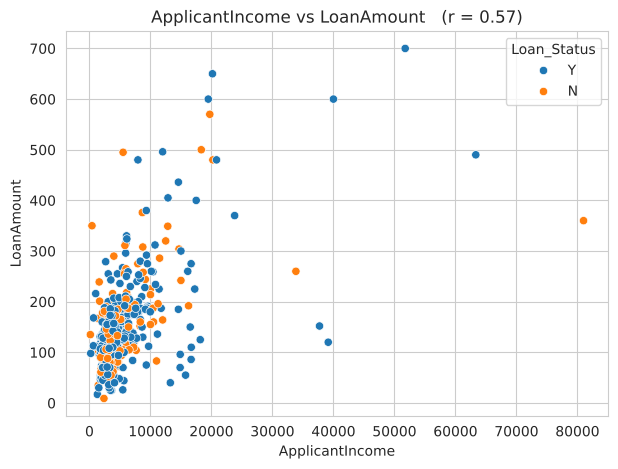

CoapplicantIncome vs LoanAmount   r = 0.19


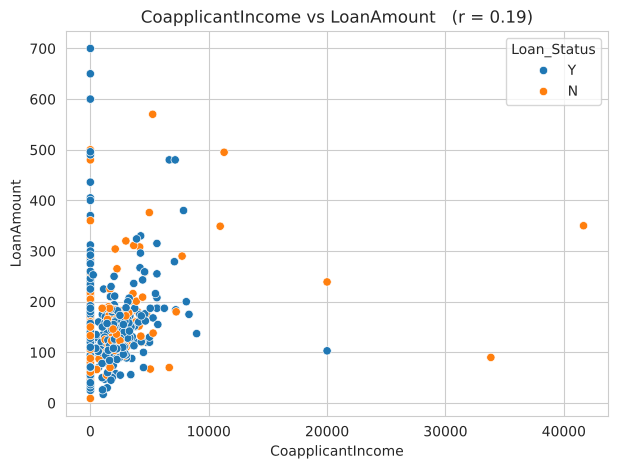

Loan_Amount_Term vs LoanAmount   r = 0.04


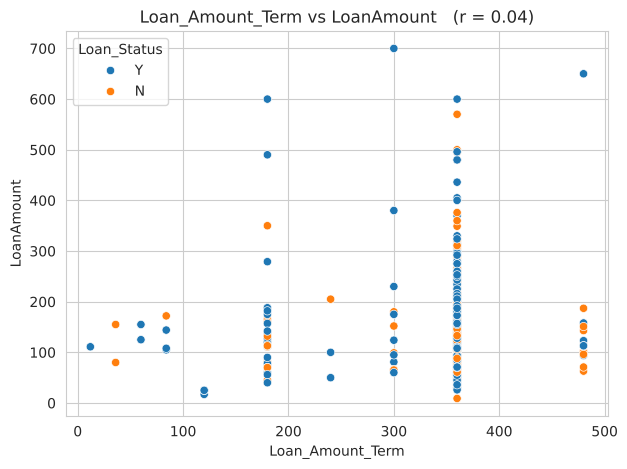

In [ ]:
def correlation(a, b):
    data = df[[a, b]].dropna()
    A, B = data[a], data[b]
    n = len(data)
    return ((A * B).sum() - n * A.mean() * B.mean()) / (n * A.std(ddof=0) * B.std(ddof=0))

pairs = [('ApplicantIncome', 'LoanAmount'),
         ('CoapplicantIncome', 'LoanAmount'),
         ('Loan_Amount_Term', 'LoanAmount')]

for x, y in pairs:
    r = correlation(x, y)
    print(x, 'vs', y, '  r =', round(r, 2))
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=x, y=y, hue=target)
    plt.title(x + ' vs ' + y + '   (r = ' + str(round(r, 2)) + ')')
    plt.show()

#### 7. Class Label Distribution

The class label Loan_Status has two classes: **Y with 422 instances (68.73%)** and **N with 192 instances (31.27%)**.

The dataset is **imbalanced** because the number of approved loans is much higher than the number of rejected loans. This should be considered when evaluating the classification results.

Number of classes: 2

Count of each class:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Percentage of each class:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


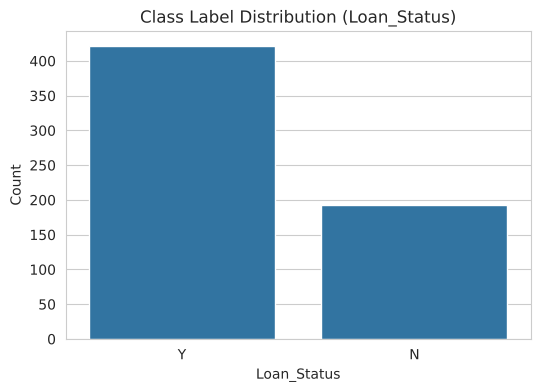

In [ ]:
class_counts = df[target].value_counts()
class_percent = df[target].value_counts(normalize=True) * 100

print('Number of classes:', df[target].nunique())
print()
print('Count of each class:')
print(class_counts)
print()
print('Percentage of each class:')
print(class_percent.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title('Class Label Distribution (Loan_Status)')
plt.xlabel('Loan_Status')
plt.ylabel('Count')
plt.show()

## [4] Data Preprocessing

Based on the data analysis, preprocessing was applied to enhance the quality of the data, since low-quality data leads to low-quality mining results. The applied tasks include **data cleaning** (handling missing values) and **data transformation** (normalization, discretization, and encoding).

### 1. Handling Missing Values

As a data cleaning task, the missing values were filled instead of ignoring the tuples, so that no records were lost. The most probable value (mode) was used for the categorical and discrete attributes (Gender, Married, Dependents, Self_Employed, Loan_Amount_Term, and Credit_History), while a measure of central tendency (median) was used for the numerical attribute LoanAmount. The median was chosen instead of the mean because LoanAmount is right-skewed and contains outliers. All missing values were handled while preserving all 614 records.

In [ ]:
mode_columns = ['Gender', 'Married', 'Dependents',
                'Self_Employed', 'Loan_Amount_Term', 'Credit_History']

for col in mode_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

### 2. Normalization

The numerical attributes had different scales, and attributes with larger ranges would have a greater effect or "weight" in the analysis. Therefore, Min-Max normalization was applied to ApplicantIncome, CoapplicantIncome, and LoanAmount, transforming their values to the range [0.0, 1.0]. This gives the attributes an equal weight while preserving their relative differences.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

columns_to_normalize = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']

scaler = MinMaxScaler()
df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

df[columns_to_normalize].head()

,ApplicantIncome,CoapplicantIncome,LoanAmount
0,0.070489,0.000000,0.172214
1,0.054830,0.036192,0.172214
2,0.035250,0.000000,0.082489
3,0.030093,0.056592,0.160637
4,0.072356,0.000000,0.191027


### 3. Discretization

Discretization divides the range of a continuous attribute into intervals, and replaces the values with interval labels. Equal-frequency binning using qcut divided LoanAmount into three intervals, each containing approximately the same number of samples, labeled as Low, Medium, and High. This made the attribute easier to interpret.

In [ ]:
df['LoanAmount_Category'] = pd.qcut(
    df['LoanAmount'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

df['LoanAmount_Category'].value_counts()

LoanAmount_Category
Medium    208
Low       206
High      200
Name: count, dtype: int64

### 4. Encoding Categorical Attributes

Encoding is a data transformation task that maps the values of an attribute to a new set of replacement values. Decision trees and K-means in scikit-learn require numeric input, so the categorical attributes were encoded:

- **Dependents:** the value "3+" was replaced with 3 and the attribute was converted to an integer.
- **Binary attributes** (Gender, Married, Education, Self_Employed) were mapped to 0 and 1.
- **Property_Area** was one-hot encoded into three columns because its values have no natural order.
- **LoanAmount_Category** was mapped to 0, 1, and 2, since its values are ordered (Low < Medium < High).
- **Loan_Status** (class label) was mapped to 1 = Approved (Y) and 0 = Rejected (N). This mapping is used in all confusion matrices in Section [6].

In [ ]:
df['Dependents'] = df['Dependents'].replace('3+', '3').astype(int)

binary_map = {'Gender': {'Male': 1, 'Female': 0},
              'Married': {'Yes': 1, 'No': 0},
              'Education': {'Graduate': 1, 'Not Graduate': 0},
              'Self_Employed': {'Yes': 1, 'No': 0},
              'Loan_Status': {'Y': 1, 'N': 0}}

for col, mapping in binary_map.items():
    df[col] = df[col].map(mapping)

df['LoanAmount_Category'] = df['LoanAmount_Category'].map({'Low': 0, 'Medium': 1, 'High': 2}).astype(int)

df = pd.get_dummies(df, columns=['Property_Area'], dtype=int)

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,LoanAmount_Category,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,LP001002,1,0,0,1,0,0.070489,0.000000,0.172214,360.0,1.0,1,1,0,0,1
1,LP001003,1,1,1,1,0,0.054830,0.036192,0.172214,360.0,1.0,0,1,1,0,0
2,LP001005,1,1,0,1,1,0.035250,0.000000,0.082489,360.0,1.0,1,0,0,0,1
3,LP001006,1,1,0,0,0,0.030093,0.056592,0.160637,360.0,1.0,1,1,0,0,1
4,LP001008,1,0,0,1,0,0.072356,0.000000,0.191027,360.0,1.0,1,1,0,0,1


### 5. Comparison: Before and After Preprocessing

After preprocessing, missing values were handled, selected numerical attributes were normalized to the range [0,1], LoanAmount was discretized into Low, Medium, and High categories, and all categorical attributes were encoded into numeric values. The preprocessed dataset is complete, consistent, and ready for classification and clustering while preserving all 614 records.

In [ ]:
raw_df = pd.read_csv(url)

print("=== Raw Dataset (Before Preprocessing) ===")
display(raw_df.head(5))

print("\n=== Preprocessed Dataset (After Preprocessing) ===")
display(df.head(5))

=== Raw Dataset (Before Preprocessing) ===


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



=== Preprocessed Dataset (After Preprocessing) ===


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,LoanAmount_Category,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,LP001002,1,0,0,1,0,0.070489,0.000000,0.172214,360.0,1.0,1,1,0,0,1
1,LP001003,1,1,1,1,0,0.054830,0.036192,0.172214,360.0,1.0,0,1,1,0,0
2,LP001005,1,1,0,1,1,0.035250,0.000000,0.082489,360.0,1.0,1,0,0,0,1
3,LP001006,1,1,0,0,0,0.030093,0.056592,0.160637,360.0,1.0,1,1,0,0,1
4,LP001008,1,0,0,1,0,0.072356,0.000000,0.191027,360.0,1.0,1,1,0,0,1


In [ ]:
df.to_csv('Preprocessed_dataset.csv', index=False)

## [5] Data Mining Technique

### Classification: Decision Tree

A Decision Tree classifier is used to predict Loan_Status. The tree is constructed in a top-down recursive divide-and-conquer manner, where an attribute selection measure is used to choose the attribute that best separates the tuples into pure partitions at each node. It was chosen because it produces clear, interpretable IF-THEN rules that show which attributes affect loan approval and how the decision is made.

Two attribute selection measures are compared:
- **Information Gain (Entropy):** the attribute with the highest information gain is chosen as the splitting attribute.
- **Gini Index:** the attribute that minimizes the Gini index (impurity) is chosen as the splitting attribute.

The dataset is partitioned using the **holdout method**, where the data is divided into two independent sets: a training set used for model construction and a testing set used for accuracy estimation. **Stratified sampling** is used so that both sets keep the same proportion of approved and rejected applications, and random_state=42 is used so the results can be reproduced.

- **Package:** `sklearn.tree`, `sklearn.model_selection`, `sklearn.metrics`
- **Methods:**
  - `train_test_split()` to split the data into three partitions: 90% / 10%, 80% / 20%, and 70% / 30% (training / testing).
  - `DecisionTreeClassifier(criterion="gini")` and `DecisionTreeClassifier(criterion="entropy")` to build trees using the Gini index and Information Gain.
  - `accuracy_score()` and `confusion_matrix()` to evaluate each model. Since the dataset is imbalanced, accuracy alone may be misleading, so the confusion matrix is used to examine how well each class is recognized.
  - `plot_tree()` to visualize the final decision tree.

### Clustering: K-means

K-means is a partitioning method that assigns each object to the cluster with the nearest centroid based on Euclidean distance, then updates the centroids until the assignment no longer changes. It was chosen because it is efficient and suitable for numeric data. The class label Loan_Status is removed before clustering, since clustering is an unsupervised task.

Since K-means is sensitive to the initial seeds, a fixed `random_state` is used so that the results are consistent.

- **Package:** `sklearn.cluster`, `sklearn.metrics`
- **Methods:**
  - `KMeans(n_clusters=k)` to apply clustering with at least three different values of K.
  - `inertia_` to compute the total within-cluster sum of squares (WSS) for K = 1 to 10. The turning point in the WSS curve (Elbow method) helps determine the number of clusters.
  - `silhouette_score()` to compute the average silhouette width for each K. It is an intrinsic method that measures how compact and well-separated the clusters are, with values between -1 and 1, where values closer to 1 are better. Three values of K (2, 3, and 4) are then compared using both measures.

### Feature Preparation

Attribute subset selection was applied before mining to remove irrelevant and redundant attributes:
- **Loan_ID** is an irrelevant attribute, since it is only an identifier and contains no useful information for the mining task.
- **LoanAmount_Category** was created during preprocessing to make loan amounts easier to interpret, but it is excluded from the models because it duplicates the information contained in LoanAmount.
- For clustering, **Loan_Amount_Term** and **Dependents** were also normalized to [0.0, 1.0]. Since K-means is a distance-based method, normalization prevents attributes with larger ranges from outweighing attributes with smaller ranges.

In [ ]:
X = df.drop(columns=['Loan_ID', 'Loan_Status', 'LoanAmount_Category'])
y = df['Loan_Status']

print("Features used:", X.columns.tolist())
print("X shape:", X.shape)

Features used: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area_Rural', 'Property_Area_Semiurban', 'Property_Area_Urban']
X shape: (614, 13)


In [ ]:
X_cluster = X.copy()
X_cluster[['Loan_Amount_Term', 'Dependents']] = MinMaxScaler().fit_transform(X_cluster[['Loan_Amount_Term', 'Dependents']])

X_cluster.describe().loc[['min', 'max']]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## [6] Evaluation and Comparison

### Classification

1. Data Splitting (90/10)

The dataset was split into 90% training and 10% testing to evaluate the Decision Tree classifier on unseen data. Stratified sampling was applied to preserve the class distribution of Loan_Status, resulting in 552 training records and 62 testing records.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 552
Testing records: 62


2. Decision Tree Using Gini Index (90/10)

The Decision Tree classifier was trained using the Gini index to predict Loan_Status. Gini measures the impurity of the data and helps select the best splits when building the tree.

In [ ]:
# Decision Tree using Gini
gini_tree = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
gini_tree.fit(X_train, y_train)

# Predict the test data
y_pred_gini = gini_tree.predict(X_test)

# Calculate accuracy
gini_accuracy = accuracy_score(y_test, y_pred_gini)

print("Decision Tree - Gini (90/10)")
print("Accuracy:", round(gini_accuracy, 4))

Decision Tree - Gini (90/10)
Accuracy: 0.7742


Result:

The Decision Tree model using Gini achieved an accuracy of 77.42% on the testing set. This means the model correctly predicted the loan approval status for 48 out of 62 test records, while 14 predictions were incorrect.

3. Confusion Matrix — Gini (90/10)

The confusion matrix was used to evaluate the Decision Tree predictions by comparing the actual loan status with the predicted loan status. It shows the number of correct and incorrect predictions for each class.

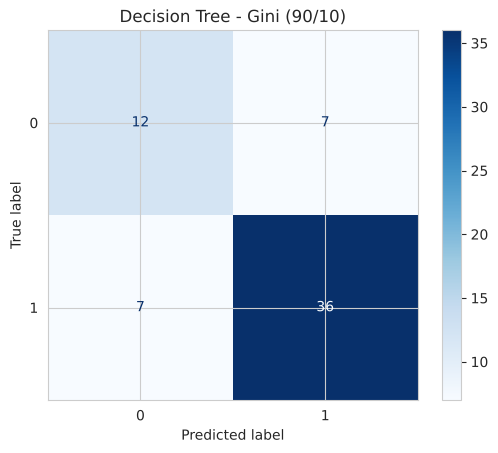

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_gini,
    labels=[0, 1],
    display_labels=['0', '1'],
    cmap='Blues'
)

plt.title('Decision Tree - Gini (90/10)')
plt.show()

Confusion Matrix Interpretation:

The model predicted 48 out of 62 applications correctly, so the accuracy was 77.42%.

For class 0 (rejected), it predicted 12 out of 19 correctly, and for class 1 (approved), it predicted 36 out of 43 correctly.

So we can see that the model predicts approved applications better than rejected ones. This is important because accuracy alone does not show the difference between the two classes.

4. Decision Tree Using Entropy (Information Gain) — 90/10

A Decision Tree classifier was trained using Entropy (Information Gain) to predict loan approval status. Entropy measures the uncertainty in the data, and Information Gain is used to select the best attribute for splitting. The same 90/10 training and testing split was used to compare its performance with the Gini model.

In [ ]:
# Decision Tree using Entropy (Information Gain)
entropy_tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

# Train the model
entropy_tree.fit(X_train, y_train)

# Predict the test data
y_pred_entropy = entropy_tree.predict(X_test)

# Calculate accuracy
entropy_accuracy = accuracy_score(y_test, y_pred_entropy)

print("Decision Tree - Entropy (90/10)")
print("Accuracy:", round(entropy_accuracy, 4))

Decision Tree - Entropy (90/10)
Accuracy: 0.7419


Result:

The Decision Tree using Entropy achieved an accuracy of 74.19%, correctly classifying 46 out of 62 testing records. Compared to Gini (77.42%), Entropy achieved a slightly lower accuracy using the same 90/10 split.

5. Confusion Matrix — Entropy (90/10)

The confusion matrix was used to evaluate the predictions of the Decision Tree using Entropy. It compares the actual and predicted loan statuses to identify correct and incorrect classifications for each class.

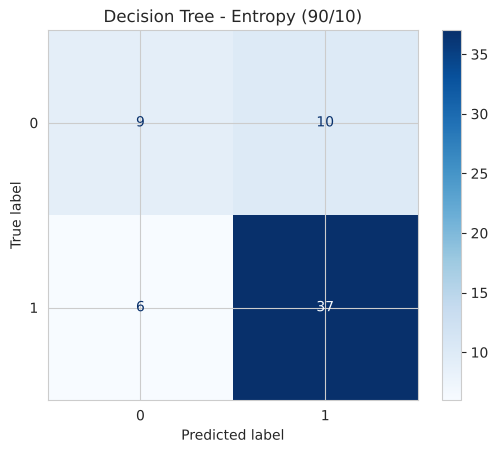

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_entropy,
    labels=[0, 1],
    display_labels=['0', '1'],
    cmap='Blues'
)

plt.title('Decision Tree - Entropy (90/10)')
plt.show()

Confusion Matrix Interpretation

The Entropy model predicted 46 out of 62 applications correctly, with an accuracy of 74.19%.

For class 0 (rejected), it predicted 9 out of 19 correctly. For class 1 (approved), it predicted 37 out of 43 correctly.

The model was better at predicting approved applications than rejected ones. It also made more incorrect predictions than Gini with the same 90/10 split.

6. Data Splitting (80% Training / 20% Testing)

The dataset was divided into 80% training data and 20% testing data to evaluate the Decision Tree classifier with a different split ratio. Stratified sampling was used to maintain the class distribution, and a fixed random state was applied to ensure reproducible results.

In [ ]:
# Split the dataset into 80% training and 20% testing
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train_80))
print("Testing records:", len(X_test_80))

Training records: 491
Testing records: 123


7. Decision Tree Using Gini Index (80/20)

A Decision Tree classifier was trained using the Gini index with 80% of the dataset for training and 20% for testing. The model was evaluated using accuracy to measure how well it predicts loan approval status on unseen data.

In [ ]:
# Decision Tree using Gini (80/20)
gini_tree_80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
gini_tree_80.fit(X_train_80, y_train_80)

# Predict the test data
y_pred_gini_80 = gini_tree_80.predict(X_test_80)

# Calculate accuracy
gini_accuracy_80 = accuracy_score(y_test_80, y_pred_gini_80)

print("Decision Tree - Gini (80/20)")
print("Accuracy:", round(gini_accuracy_80, 4))

Decision Tree - Gini (80/20)
Accuracy: 0.748


Result:

The Decision Tree using Gini achieved an accuracy of 74.80%, correctly classifying 92 out of 123 testing records. The remaining 31 records were incorrectly classified. Compared to the 90/10 split (77.42%), the accuracy decreased slightly when using the 80/20 split.

8. Confusion Matrix — Gini (80/20)

The confusion matrix was used to evaluate the Decision Tree using Gini with the 80/20 split. It compares the actual and predicted loan statuses to show the number of correct and incorrect predictions for each class.

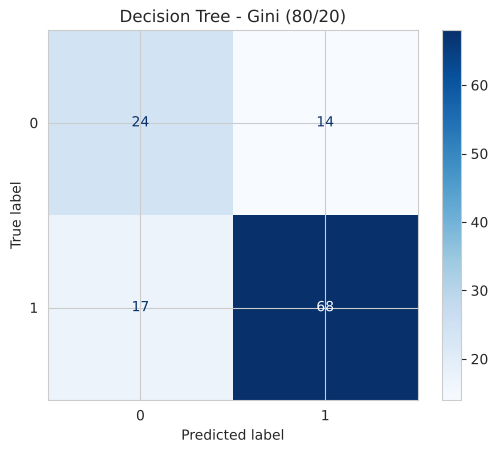

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_80,
    y_pred_gini_80,
    labels=[0, 1],
    display_labels=['0', '1'],
    cmap='Blues'
)

plt.title('Decision Tree - Gini (80/20)')
plt.show()

Confusion Matrix Interpretation:

The confusion matrix shows that the Decision Tree using Gini correctly classified 24 records from class 0 and 68 records from class 1. However, 14 records from class 0 were incorrectly predicted as class 1, while 17 records from class 1 were incorrectly predicted as class 0. Overall, the model correctly classified 92 out of 123 testing records, achieving an accuracy of 74.80%.

9. Decision Tree Using Entropy (Information Gain) — 80/20

A Decision Tree classifier was trained using Entropy (Information Gain) with 80% of the dataset for training and 20% for testing. Entropy was used to measure uncertainty and select the best splits. The model’s accuracy was evaluated and will be compared with the Gini model using the same split ratio.

In [ ]:
# Decision Tree using Entropy (80/20)
entropy_tree_80 = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

# Train the model
entropy_tree_80.fit(X_train_80, y_train_80)

# Predict the test data
y_pred_entropy_80 = entropy_tree_80.predict(X_test_80)

# Calculate accuracy
entropy_accuracy_80 = accuracy_score(y_test_80, y_pred_entropy_80)

print("Decision Tree - Entropy (80/20)")
print("Accuracy:", round(entropy_accuracy_80, 4))

Decision Tree - Entropy (80/20)
Accuracy: 0.7236


Result:

The Decision Tree using Entropy achieved an accuracy of 72.36%, correctly classifying 89 out of 123 testing records, while 34 records were incorrectly classified. Compared to Gini (74.80%), Entropy achieved a lower accuracy using the same 80/20 split.

10. Confusion Matrix — Entropy (80/20)

The confusion matrix was used to evaluate the Decision Tree using Entropy with the 80/20 split. It compares the actual and predicted loan statuses to identify the correct and incorrect predictions for each class.

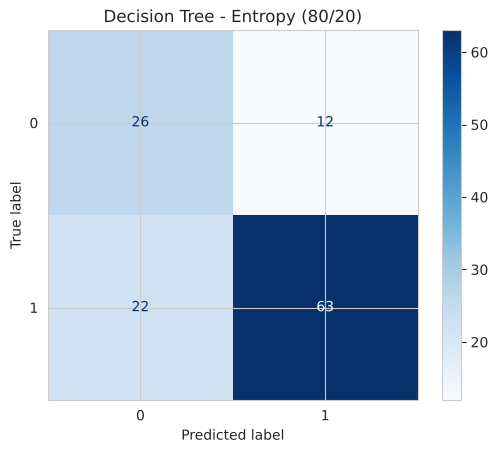

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_80,
    y_pred_entropy_80,
    labels=[0, 1],
    display_labels=['0', '1'],
    cmap='Blues'
)

plt.title('Decision Tree - Entropy (80/20)')
plt.show()

Confusion Matrix Interpretation:

The confusion matrix shows that the Decision Tree using Entropy correctly classified 26 records from class 0 and 63 records from class 1. However, 12 records from class 0 were incorrectly predicted as class 1, while 22 records from class 1 were incorrectly predicted as class 0. Overall, the model correctly classified 89 out of 123 testing records, achieving an accuracy of 72.36%.

11. Data Splitting (70% Training / 30% Testing)

The dataset was divided into 70% training data and 30% testing data to evaluate the Decision Tree classifier using a larger testing set. Stratified sampling was applied to preserve the class distribution, and a fixed random state was used to ensure reproducible results.

In [ ]:
# Split the dataset into 70% training and 30% testing
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train_70))
print("Testing records:", len(X_test_70))

Training records: 429
Testing records: 185


Result:

The dataset contains 614 records. After applying the 70/30 split, 429 records (70%) were used for training and 185 records (30%) were used for testing. This split allows the Decision Tree models to be trained on one portion of the data and evaluated on unseen records.

12. Decision Tree Using Gini Index (70/30)

A Decision Tree classifier was trained using the Gini index with 70% of the dataset for training and 30% for testing. The model was evaluated using accuracy to measure its ability to correctly predict loan approval status on unseen data. The results will be compared with the previous 90/10 and 80/20 splits.

In [ ]:
# Decision Tree using Gini (70/30)
gini_tree_70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
gini_tree_70.fit(X_train_70, y_train_70)

# Predict the test data
y_pred_gini_70 = gini_tree_70.predict(X_test_70)

# Calculate accuracy
gini_accuracy_70 = accuracy_score(y_test_70, y_pred_gini_70)

print("Decision Tree - Gini (70/30)")
print("Accuracy:", round(gini_accuracy_70, 4))

Decision Tree - Gini (70/30)
Accuracy: 0.6811


Result:

The Decision Tree using Gini achieved an accuracy of 68.11%, correctly classifying 126 out of 185 testing records, while 59 records were incorrectly classified. Compared to the 90/10 split (77.42%) and 80/20 split (74.80%), the accuracy decreased when using the 70/30 split.

13. Confusion Matrix — Gini (70/30)

The confusion matrix was used to evaluate the Decision Tree using Gini with the 70/30 split. It compares the actual and predicted loan statuses to identify the number of correct and incorrect predictions for each class.

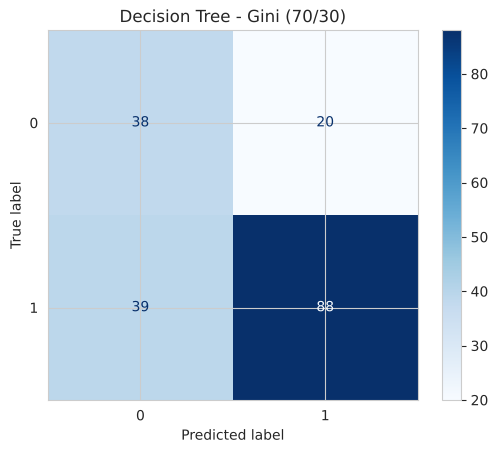

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_70,
    y_pred_gini_70,
    labels=[0, 1],
    display_labels=['0', '1'],
    cmap='Blues'
)

plt.title('Decision Tree - Gini (70/30)')
plt.show()

Confusion Matrix Interpretation:

The confusion matrix shows that the Decision Tree using Gini correctly classified 38 records from class 0 and 88 records from class 1. However, 20 records from class 0 were incorrectly predicted as class 1, while 39 records from class 1 were incorrectly predicted as class 0. Overall, the model correctly classified 126 out of 185 testing records, achieving an accuracy of 68.11%.

14. Decision Tree Using Entropy (Information Gain) — 70/30

A Decision Tree classifier was trained using Entropy (Information Gain) with 70% of the dataset for training and 30% for testing. Entropy was used to measure uncertainty and select the best splits. The model was evaluated using accuracy to compare its performance with Gini and the previous training/testing ratios.

In [ ]:
# Decision Tree using Entropy (70/30)
entropy_tree_70 = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

# Train the model
entropy_tree_70.fit(X_train_70, y_train_70)

# Predict the test data
y_pred_entropy_70 = entropy_tree_70.predict(X_test_70)

# Calculate accuracy
entropy_accuracy_70 = accuracy_score(
    y_test_70, y_pred_entropy_70
)

print("Decision Tree - Entropy (70/30)")
print("Accuracy:", round(entropy_accuracy_70, 4))

Decision Tree - Entropy (70/30)
Accuracy: 0.6703


Result:

The Decision Tree using Entropy achieved an accuracy of 67.03%, correctly classifying 124 out of 185 testing records, while 61 records were incorrectly classified. Compared to Gini (68.11%) using the same 70/30 split, Entropy achieved a slightly lower accuracy.

15. Confusion Matrix — Entropy (70/30)

The confusion matrix was used to evaluate the Decision Tree classifier using Entropy with the 70/30 split. It compares the actual and predicted loan approval statuses to show the number of correct and incorrect predictions for each class.

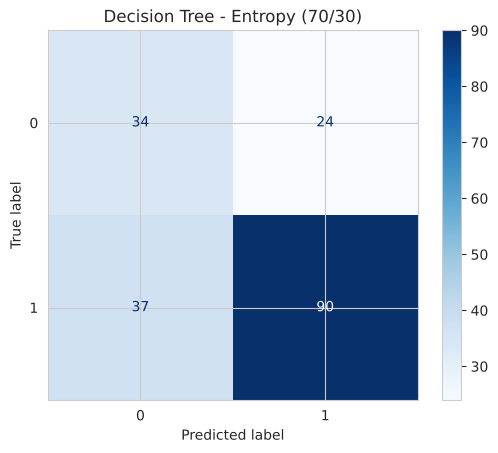

In [ ]:
# Confusion Matrix for Entropy (70/30)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_70,
    y_pred_entropy_70,
    labels=[0, 1],
    display_labels=['0', '1'],
    cmap='Blues'
)

plt.title('Decision Tree - Entropy (70/30)')
plt.show()

Confusion Matrix Interpretation:

The confusion matrix shows that the Decision Tree using Entropy correctly classified 34 records from class 0 and 90 records from class 1. However, 24 records from class 0 were incorrectly predicted as class 1, while 37 records from class 1 were incorrectly predicted as class 0. Overall, the model correctly classified 124 out of 185 testing records, achieving an accuracy of 67.03%.

16. Accuracy Comparison of Decision Tree Models

Six Decision Tree models were evaluated using three training/testing ratios (90/10, 80/20, and 70/30) and two splitting criteria (Gini Index and Entropy/Information Gain). The accuracy scores were collected in a comparison table to evaluate the effect of different splitting criteria and training/testing ratios on the model’s performance.

In [ ]:

import pandas as pd

# Gini Accuracy Comparison
gini_results = pd.DataFrame({
    '90/10': [round(gini_accuracy * 100, 2)],
    '80/20': [round(gini_accuracy_80 * 100, 2)],
    '70/30': [round(gini_accuracy_70 * 100, 2)]
}, index=['Accuracy (%)'])

print("Gini Index")
display(gini_results)

# Entropy Accuracy Comparison
entropy_results = pd.DataFrame({
    '90/10': [round(entropy_accuracy * 100, 2)],
    '80/20': [round(entropy_accuracy_80 * 100, 2)],
    '70/30': [round(entropy_accuracy_70 * 100, 2)]
}, index=['Accuracy (%)'])

print("Entropy (Information Gain)")
display(entropy_results)


Gini Index


,90/10,80/20,70/30
Accuracy (%),77.42,74.8,68.11


Entropy (Information Gain)


,90/10,80/20,70/30
Accuracy (%),74.19,72.36,67.03


Results and Comparison

From the results, Gini gave higher accuracy than Entropy in all three splits, but the difference was small.

For 90/10, Gini got 77.42% and Entropy got 74.19%. For 80/20, the results were 74.80% and 72.36%. For 70/30, they were 68.11% and 67.03%.

The highest accuracy was Gini with 90/10. However, this split has the smallest testing set, so we cannot say that it will always give the best result.

17. Decision Tree Visualization

The Decision Tree using the Gini index with the 90/10 training/testing split was selected for visualization because it achieved the highest accuracy (77.42%) among the six evaluated models. The tree visualization shows how the model splits the data based on feature values to predict loan approval status. Each node represents a decision rule, while the leaf nodes represent the final predicted classes.

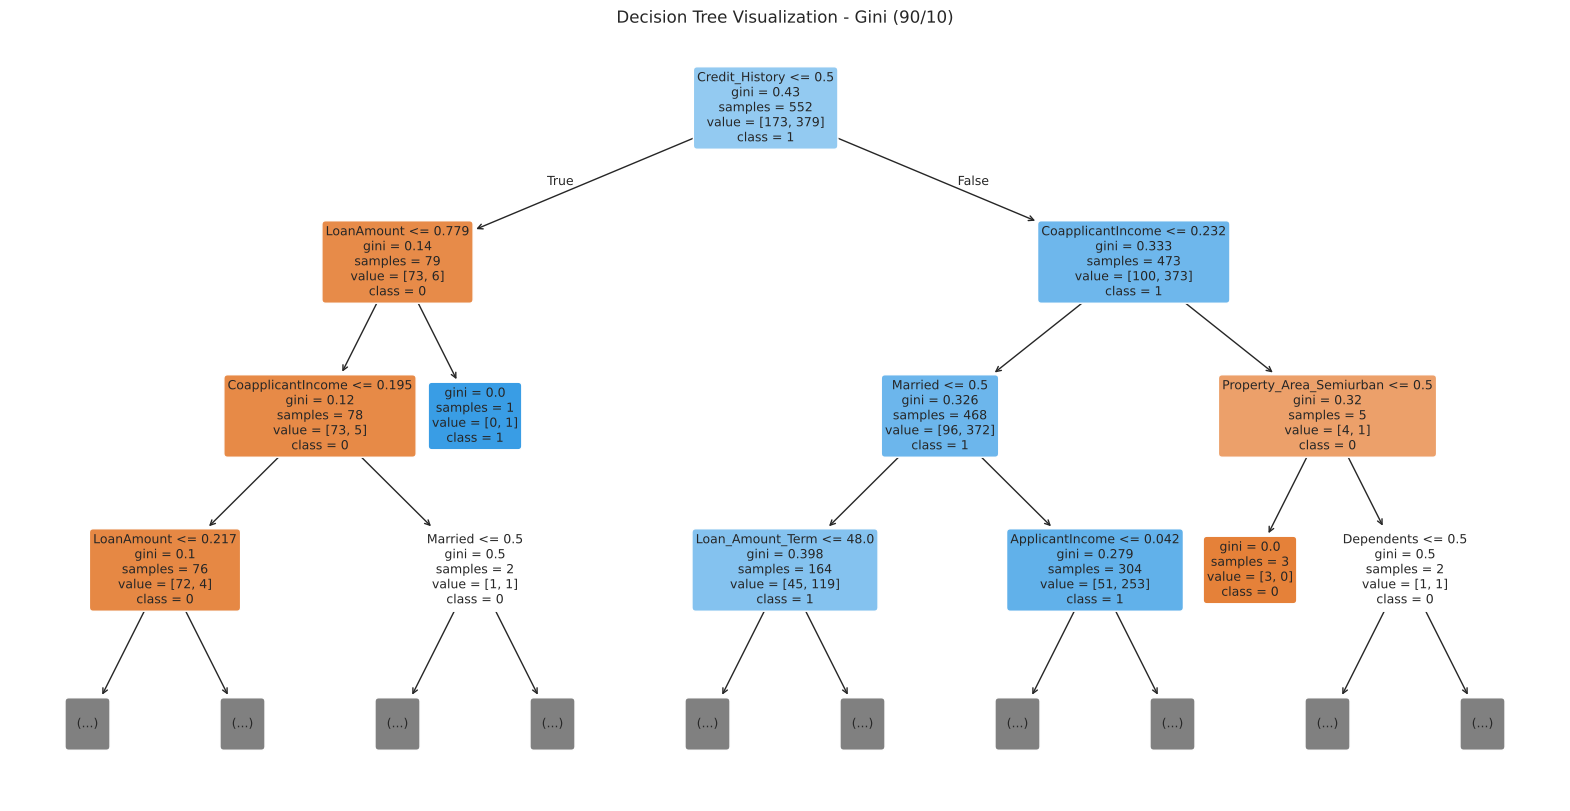

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Visualize the best-performing Decision Tree (Gini 90/10)
plt.figure(figsize=(20, 10))

plot_tree(
    gini_tree,
    feature_names=X.columns,
    class_names=['0', '1'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Decision Tree Visualization - Gini (90/10)')
plt.show()

Visualization Interpretation:

The Decision Tree visualization shows how the Gini-based classifier predicts loan approval using different features.

The first split is based on Credit_History, which divides the data into two groups. The tree then uses other features, such as LoanAmount and CoapplicantIncome, to make further decisions.

The colors represent the predicted classes (0 and 1), while the values inside each node show the number of records belonging to each class.

Only the first three levels are displayed to make the tree easier to understand. However, the complete trained model was used for prediction and accuracy evaluation.

### Clustering

K-means clustering was applied to the preprocessed Loan Prediction dataset to group applicants with similar characteristics. Unlike classification, clustering does not use the target variable Loan_Status. The clustering results will be evaluated using the Elbow Method and Silhouette Coefficient to identify the optimal number of clusters.


#### 1.  Data Preparation for Clustering

The clustering dataset was checked to ensure that all attributes were numeric and contained no missing values. The dataset contains 614 records and 13 features, with values scaled between 0 and 1. Loan_Status and Loan_ID were excluded because they are not suitable features for clustering.

In [ ]:
# check the clustering dataset
print("Dataset Shape:", X_cluster.shape)

print("============================================")
print("Data Information:")
X_cluster.info()

print("============================================")
print("Missing Values:", X_cluster.isnull().sum())

print("============================================")
print("Statistical Summary:", X_cluster.describe())

Dataset Shape: (614, 13)
Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    float64
 3   Education                614 non-null    int64  
 4   Self_Employed            614 non-null    int64  
 5   ApplicantIncome          614 non-null    float64
 6   CoapplicantIncome        614 non-null    float64
 7   LoanAmount               614 non-null    float64
 8   Loan_Amount_Term         614 non-null    float64
 9   Credit_History           614 non-null    float64
 10  Property_Area_Rural      614 non-null    int64  
 11  Property_Area_Semiurban  614 non-null    int64  
 12  Property_Area_Urban      614 non-null    int64  
dtypes: float64(6), int64(7)
memory usage: 62.5 KB
Mi

The results confirm that the dataset has been encoded and scaled, making it suitable for applying K-means clustering. The target variable (Loan_Status) and the identifier (Loan_ID) were excluded to ensure that the clustering is based only on applicants' characteristics.



#### 2. Elbow Method for Optimal K

The Elbow Method was used to evaluate different values of K by calculating the total within-cluster sum of squares (WSS). This helps identify the point where increasing the number of clusters provides smaller improvements.



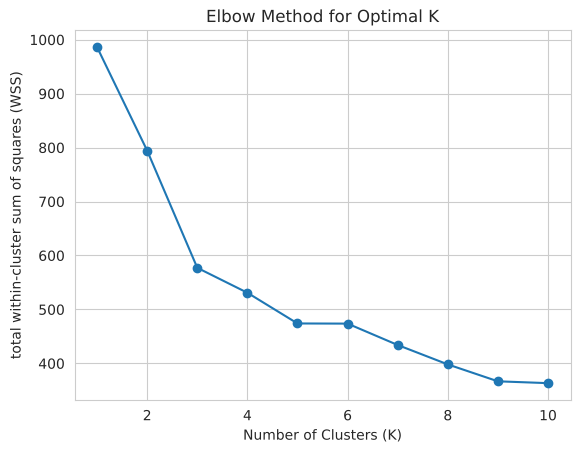

In [ ]:
from sklearn.cluster import KMeans
# Perform K-means clustering for different values of K
wss_values = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_cluster)
    wss_values.append(kmeans.inertia_)

# Plot the Elbow Method
plt.plot(range(1, 11), wss_values, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('total within-cluster sum of squares (WSS)')
plt.show()


The WSS decreases substantially as K increases from 1 to 3, after which the improvement becomes more gradual. This suggests an elbow around K=3. However, the elbow is not perfectly sharp, so the Silhouette Score is also used to evaluate the appropriate number of clusters.

#### 3. Silhouette Analysis

The Silhouette Coefficient was used to evaluate clustering quality for different values of K. It measures how closely data points are grouped within their clusters and how well the clusters are separated from each other.



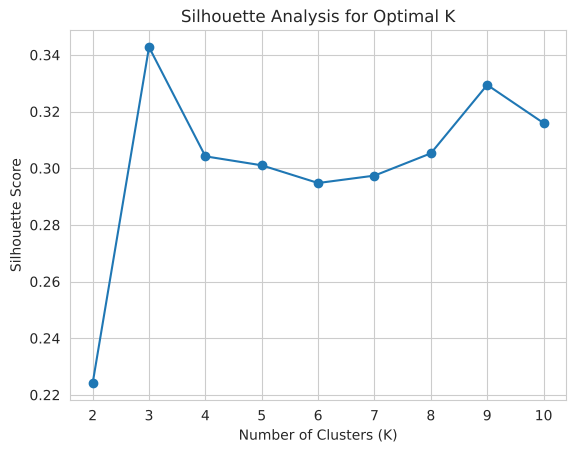

In [ ]:
from sklearn.metrics import silhouette_score

# Perform Silhouette Analysis for different values of K
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_cluster)
    score = silhouette_score(X_cluster, kmeans.labels_)
    silhouette_scores.append(score)

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Analysis for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.show()

K=3 achieved the highest Silhouette Score (approximately 0.343) among the tested values from K=2 to K=10, followed by K=9 (approximately 0.329).

Although K=3 performed best, its score indicates moderate rather than strong cluster separation. This suggests that some overlap exists between the clusters.

#### 4. K-means Clustering Comparison

K-means clustering was applied using three different values of K (2, 3, and 4).

The models were evaluated using the Silhouette Score and total within-cluster sum of squares (WSS) to compare clustering quality and identify the most suitable number of clusters.

In [ ]:
# compare three K values
k_values = [2, 3, 4]

results = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_cluster)

    score = silhouette_score(X_cluster, kmeans.labels_)
    wss= kmeans.inertia_

    results.append([k, score, wss])

# Create a DataFrame to display the results
results_df = pd.DataFrame(results, columns=['K', 'Silhouette Score', 'WSS'])

# Display the results (comparison table)
print(results_df)


   K  Silhouette Score         WSS
0  2          0.224132  794.303839
1  3          0.342736  577.136051
2  4          0.304196  530.946386


Among the three evaluated models, K=3 achieved the highest Silhouette Score (0.3427), compared to K=2 (0.2241) and K=4 (0.3042), providing the best balance between compactness and separation. The detailed comparison of K=2 and K=4 is discussed below.


| | K=2 | K=3 | K=4 |
|---|---|---|---|
| Average Silhouette width | 0.2241 | 0.3427 | 0.3042 |
| Total within-cluster sum of squares | 794.30 | 577.14 | 530.95 |


In [ ]:
for k in [2,4]:
  km = KMeans(n_clusters=k, random_state=42).fit(X_cluster)
  print(f"K={k}")
  display(pd.DataFrame(km.cluster_centers_, columns=X_cluster.columns).round(3))

K=2


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,0.866,0.648,0.248,0.732,0.145,0.067,0.039,0.206,0.713,0.844,1.0,-0.000,0.000
1,0.798,0.655,0.248,0.802,0.129,0.064,0.039,0.195,0.703,0.860,0.0,0.536,0.464


K=4


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,0.698,-0.000,0.106,0.730,0.079,0.060,0.029,0.189,0.750,0.873,1.0,0.0,-0.0
1,0.837,0.653,0.248,0.802,0.119,0.065,0.041,0.192,0.687,0.847,0.0,-0.0,1.0
2,0.764,0.657,0.249,0.803,0.137,0.064,0.036,0.197,0.716,0.871,0.0,1.0,0.0
3,0.957,1.000,0.325,0.733,0.181,0.071,0.045,0.215,0.694,0.828,1.0,0.0,-0.0



**K=2** The lowest Silhouette (0.2241)
and the highest WSS (794.30) among the three values, so two clusters are too coarse and group dissimilar applicants together.

The cluster centers show that the split is based on Property_Area: Cluster 0 contains only Rural applicants (Property_Area_Rural = 1.0), while Cluster 1 merges Semiurban (0.536) and Urban (0.464) applicants. The remaining features are very similar in both clusters (for example, scaled ApplicantIncome is 0.067 and 0.064, and Credit_History is 0.844 and 0.860).




---




**K=4** WSS decreased to 530.95, but this is expected because WSS always decreases as K increases. The Silhouette dropped to 0.3042, so the extra cluster did not improve separation.

The cluster centers show that Urban (Cluster 1) and Semiurban (Cluster 2) applicants each form one cluster, while the Rural applicants are split into two clusters based on marital status: Cluster 0 contains unmarried applicants (Married = 0.0) and Cluster 3 contains only married applicants (Married = 1.0). The other features remain close across the clusters. Therefore, the fourth cluster adds a small amount of detail (Married within Rural) but does not make the clusters better separated.

#### 5. Cluster Visualization

The clustering results for K=2, K=3, K=4 were visualized using scatter plots. ApplicantIncome and LoanAmount were selected to display the clusters in two dimensions, with different colors representing different clusters.

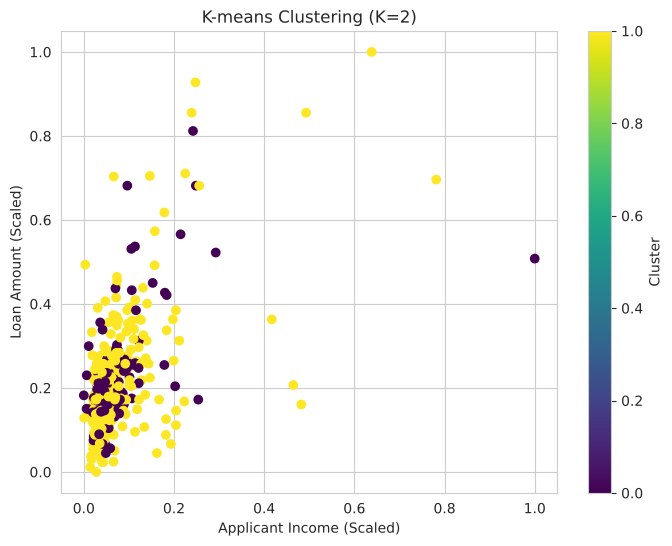

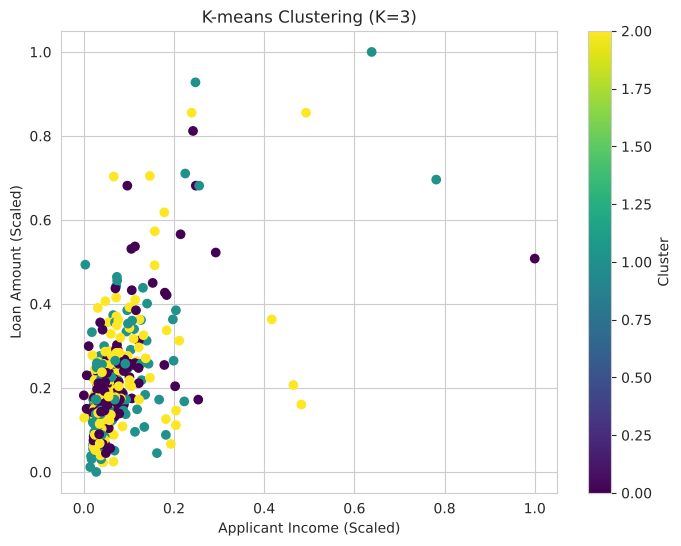

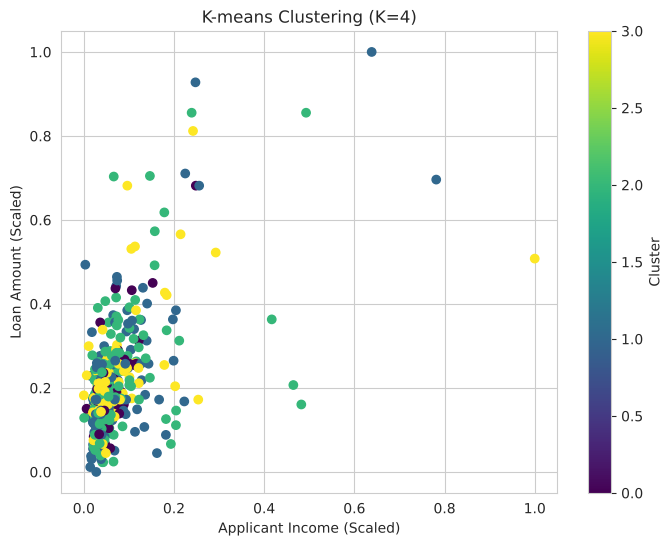

In [ ]:
# Visualize clusters for different K values

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_cluster)

    plt.figure(figsize=(8, 6))

    plt.scatter(
        X_cluster['ApplicantIncome'],
        X_cluster['LoanAmount'],
        c=kmeans.labels_,
        cmap='viridis'
    )

    plt.title(f'K-means Clustering (K={k})')
    plt.xlabel('Applicant Income (Scaled)')
    plt.ylabel('Loan Amount (Scaled)')
    plt.colorbar(label='Cluster')
    plt.show()


The scatter plots show considerable overlap between the clusters when visualized using ApplicantIncome and LoanAmount. Although both features were included in the K-means clustering process, the plots display only two of the 13 features used by the model.

The Property_Area features have a stronger influence on the clustering results because they are represented by binary values (0 or 1), while the scaled income values are relatively small. Therefore, these two-dimensional plots do not fully represent the separation between clusters across all features.

#### 6. Optimal Number of Clusters

The optimal number of clusters is selected by considering the Elbow Method and the Silhouette Score.


---


Results and Interpretation:

Both the Elbow Method and Silhouette Analysis suggest that K=3 is the best choice for our dataset.


*   Elbow Method: K=3, based on the observed bend in the WSS curve.
*   Silhouette Analysis: K=3, with the highest average Silhouette Score of 0.3427 among the tested values.

The scatter plots were used to visualize the clustering results, but they were not used as an independent criterion for selecting K because they display only two features.

Therefore, K=3 was selected as the optimal number of clusters based on the agreement between the two evaluation methods. However, the Silhouette Score indicates that the clusters have limited to moderate separation.




#### 7. Cluster Interpretation

The final K-means model is fitted using K=3. The cluster centers are examined to identify the main characteristics of each group and understand how applicants differ across the selected features.

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_cluster)

centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X_cluster.columns
)

display(centers)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,0.865922,0.648045,0.247672,0.731844,0.145251,0.066841,0.039493,0.206146,0.713365,0.843575,1.000000e+00,-8.326673e-16,5.551115e-16
1,0.836634,0.653465,0.247525,0.801980,0.118812,0.064913,0.041192,0.191644,0.687484,0.846535,5.551115e-17,-1.221245e-15,1.000000e+00
2,0.763948,0.656652,0.248927,0.802575,0.137339,0.063602,0.036483,0.197003,0.716408,0.871245,5.551115e-17,1.000000e+00,9.992007e-16


The cluster centers show that the three clusters are primarily separated by Property_Area:



*   Cluster 0: Rural applicants.
*   Cluster 1: Urban applicants.
*   Cluster 2: Semiurban applicants.


The Property_Area columns have centroid values approximately equal to 1 for corresponding area and 0 for the other areas.


Other features, such as ApplicantIncome, LoanAmount, and Credit_History, show relatively small differences between the cluster centers. For example, the scaled ApplicantIncome values are 0.0668, 0.0649, and 0.0636.


This suggests that Property_Area has a strong influence on the clustering results. The binary Property_Area features (0 or 1) contribute more to the Euclidean distance than the relatively small scaled income values.

Therefore, the clusters mainly reflect property locations rather than distinct financial profiles. Since Loan_Status was excluded from clustering, these groups should not be interpreted as loan approval categories.


## [7] Findings and Discussion

### 1. Classification Findings

The classification results showed that the Decision Tree using Gini achieved slightly higher accuracy than Entropy in all three data splits (90/10, 80/20, and 70/30). The differences were relatively small, ranging from 1.08 to 3.23 percentage points. The highest accuracy was 77.42% using Gini with the 90/10 split. However, this split used only 62 testing records, so the result should be interpreted carefully.

As shown in the Decision Tree visualization in Section [6], the first split was based on Credit_History. A value of 1 means that the applicant's credit history meets the credit guidelines, while 0 means it does not. Other attributes, such as LoanAmount and CoapplicantIncome, were also used in the following splits.

The dataset was imbalanced, with 422 approved loans and 192 rejected loans. Therefore, accuracy alone does not fully explain the model's performance.

The confusion matrix for Gini with the 90/10 split showed that the model correctly identified only 12 out of 19 rejected loans (63.16%), compared to 36 out of 43 approved loans (83.72%). This indicates that the model was better at recognizing Class 1 (approved loans) than Class 0 (rejected loans).

Overall, Gini achieved slightly better accuracy in our experiments, but the model had more difficulty identifying rejected applications. Further evaluation is needed to improve the reliability of its predictions.

2. Clustering Findings

K-means clustering was used to group loan applicants with similar characteristics. The Elbow Method and Silhouette Score were used to compare possible values of K. K=3 gave the highest Silhouette Score (0.3427) among the tested values and was supported by the Elbow Method. The cluster scatter plots for K=2, K=3, and K=4 are presented in Section [6].

To understand what makes each group different, the following charts compare the Property_Area distribution and the average values of relevant applicant attributes for K=3. These plots describe the actual features used by the model, rather than only the two axes shown in the scatter plot.

In [ ]:
#  Describe clusters using the final K=3 model from Section [6].

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cluster_profile = X_cluster.copy()
cluster_profile['Cluster'] = kmeans.labels_

area_cols = [
    'Property_Area_Rural',
    'Property_Area_Urban',
    'Property_Area_Semiurban'
]
cluster_profile['Property_Area'] = (
    cluster_profile[area_cols].idxmax(axis=1)
    .str.replace('Property_Area_', '', regex=False)
)

cluster_sizes = cluster_profile.groupby('Cluster').size().rename('Number of Applicants')
area_percent = pd.crosstab(
    cluster_profile['Cluster'],
    cluster_profile['Property_Area'],
    normalize='index'
).mul(100)

features = ['ApplicantIncome', 'LoanAmount', 'Credit_History', 'Dependents']
feature_means = cluster_profile.groupby('Cluster')[features].mean()

print('Number of applicants in each cluster:')
display(cluster_sizes.to_frame())
print('Property area percentages within each cluster:')
display(area_percent.round(1))
print('Average scaled/binary feature values by cluster:')
display(feature_means.round(4))


Number of applicants in each cluster:


,Number of Applicants
Cluster,
0,179
1,202
2,233


Property area percentages within each cluster:


Property_Area,Rural,Semiurban,Urban
Cluster,,,
0,100.0,0.0,0.0
1,0.0,0.0,100.0
2,0.0,100.0,0.0


Average scaled/binary feature values by cluster:


,ApplicantIncome,LoanAmount,Credit_History,Dependents
Cluster,,,,
0,0.0668,0.2061,0.8436,0.2477
1,0.0649,0.1916,0.8465,0.2475
2,0.0636,0.1970,0.8712,0.2489


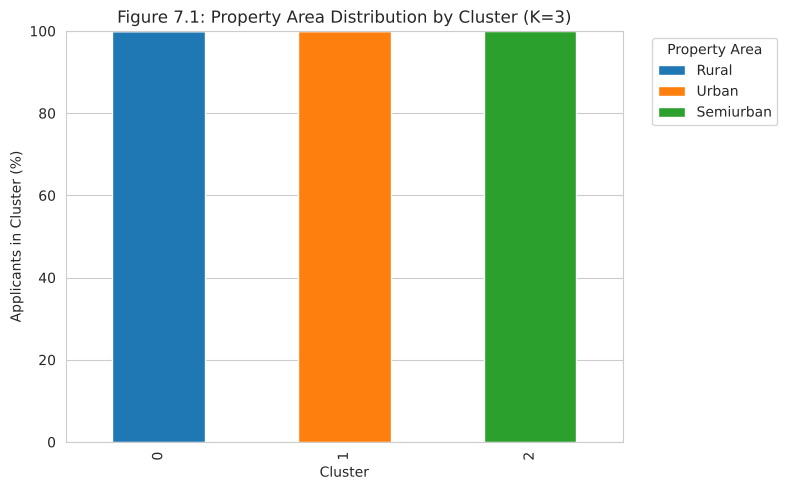

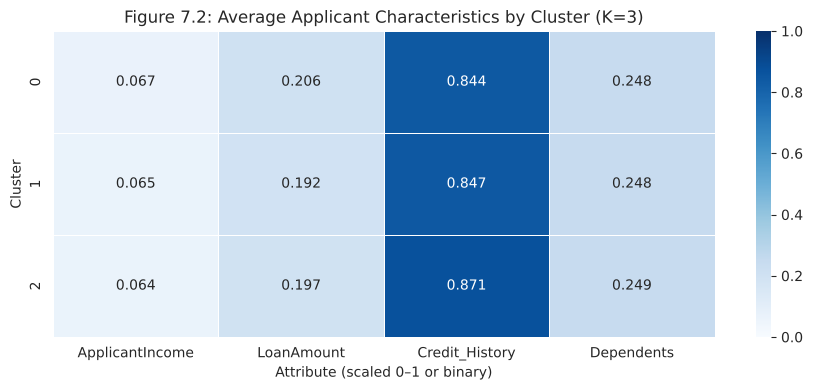

In [ ]:
# Figure 7.1: Property Area distribution for the final K=3 clusters.
ax = area_percent.reindex(columns=['Rural', 'Urban', 'Semiurban'], fill_value=0).plot(
    kind='bar', stacked=True, figsize=(8, 5)
)
ax.set_title('Figure 7.1: Property Area Distribution by Cluster (K=3)')
ax.set_xlabel('Cluster')
ax.set_ylabel('Applicants in Cluster (%)')
ax.set_ylim(0, 100)
ax.legend(title='Property Area', bbox_to_anchor=(1.04, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Figure 7.2: Compare selected applicant features across clusters.
plt.figure(figsize=(9, 4))
sns.heatmap(feature_means, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1,
            linewidths=0.5)
plt.title('Figure 7.2: Average Applicant Characteristics by Cluster (K=3)')
plt.xlabel('Attribute (scaled 0–1 or binary)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()


**Interpretation of Figures 7.1 and 7.2:**

- **Cluster 0 (179 applicants):** This group contains applicants from Rural areas.
- **Cluster 1 (202 applicants):** This group contains applicants from Urban areas.
- **Cluster 2 (233 applicants):** This group contains applicants from Semiurban areas and has an average Credit_History value of 0.8712.

Figure 7.1 shows that Property_Area is the main feature separating the three clusters.

Figure 7.2 shows that the financial attributes have relatively small differences between the groups. For example, the average scaled ApplicantIncome values are 0.0668, 0.0649, and 0.0636 for Clusters 0, 1, and 2, respectively. These values are very close, so the difference in income is not a strong distinguishing characteristic.

The results suggest that the clusters are mainly separated by property location rather than clear differences in financial characteristics.

The Silhouette Score of 0.3427 also indicates that the clusters are not strongly separated across all features. Overall, these visualizations help us understand the similarities and differences between applicants.

3. Comparison with the Research Paper

Our results were compared with the research paper by Gawande et al. [1], which also focused on loan approval prediction.

The study used several machine learning models, including Decision Tree, Random Forest, and XGBoost. Its Decision Tree achieved 81.87% accuracy using the 80/20 split, while our Decision Tree using Gini achieved 74.80% with the same split ratio.

The research paper also achieved 95.16% accuracy using an ensemble model combining Random Forest and XGBoost.

Both our project and the research paper highlighted the importance of Credit_History in predicting loan approval.

However, the research paper reported 13,508 records, while our dataset contains 614 records. The models and preprocessing methods were also different, so the accuracy results cannot be directly compared under identical conditions.

### 4. Overall Findings and Conclusion

In this project, we used Decision Tree to predict loan approval and K-means to group applicants with similar characteristics.

For classification, Gini with the 90/10 split gave the highest accuracy (77.42%). The difference between Gini and Entropy was small in all three splits. Also, the model predicted approved applications better than rejected ones, so accuracy alone was not enough to explain the results.

For clustering, K=3 gave the highest Silhouette Score (0.3427) among the tested values. The three clusters were mainly separated by Property_Area (Rural, Urban, and Semiurban). The income values were very close between the clusters, so income was not a major difference.

From these results, we found that Credit_History was important for loan approval prediction, while Property_Area had a strong effect on the clustering results. The classification model still had difficulty predicting rejected applications, and the clusters were not strongly separated.

## [8] References

[1] K. Gawande, Pallavi, D. Thakur, and P. Saurabh, “An explainable ensemble learning framework for transparent and accurate loan approval prediction,” Discover Artificial Intelligence, vol. 6, art. no. 1070, 2026, doi: 10.1007/s44163-026-01569-6.

[2] ufffnick, “Loan Prediction Dream Housing Finance,” Kaggle. [Online]. Available: https://www.kaggle.com/code/ufffnick/loan-prediction-dream-housing-finance/input
